In [1]:
## Load Data

import pandas as pd

df = pd.read_csv('Student_Depression_Dataset.csv')
df

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4459,Female,26,Middle class,In a Relationship,Separated,Family,11,2.97,No,Critical,12619,Khulna,Yes
4460,Male,28,Lower Middle class,Single,Unmarried,Family,8,2.60,No,Normal,2806,Rajshahi,Yes
4461,Female,23,Middle class,In a Relationship,Married,Bachelor,10,2.80,No,Good,14066,Rajshahi,No
4462,Female,23,Middle class,Complicated,Married,Family,5,3.00,Yes,Normal,14338,Barisal,No


In [2]:
## EDA
print(f'Cek 5 Data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()}')

Cek 5 Data teratas 
    Gender  Age Family_background Relationship_status Marital_status  \
0  Female   22      Middle class              Single      Unmarried   
1    Male   19      Middle class              Single      Unmarried   
2    Male   23      Middle class              Single      Unmarried   
3    Male   20      Middle class         Complicated      Unmarried   
4  Female   21      Middle class              Single      Unmarried   

  Living_style  Current_semester  CGPA friend_circle Health_condition  \
0     Bachelor                 8  3.43           Yes         Critical   
1     Bachelor                 2  3.70           Yes         Abnormal   
2       Family                 8  3.28            No         Abnormal   
3       Family                 2  3.77            No             Good   
4       Family                 1  4.00            No         Abnormal   

   Cost_without_study Home_division Depression  
0               10113    Chittagong        Yes  
1              

                         Age  Current_semester      CGPA  Cost_without_study
Age                 1.000000          0.325304 -0.065085           -0.062625
Current_semester    0.325304          1.000000 -0.007946            0.013762
CGPA               -0.065085         -0.007946  1.000000            0.081900
Cost_without_study -0.062625          0.013762  0.081900            1.000000


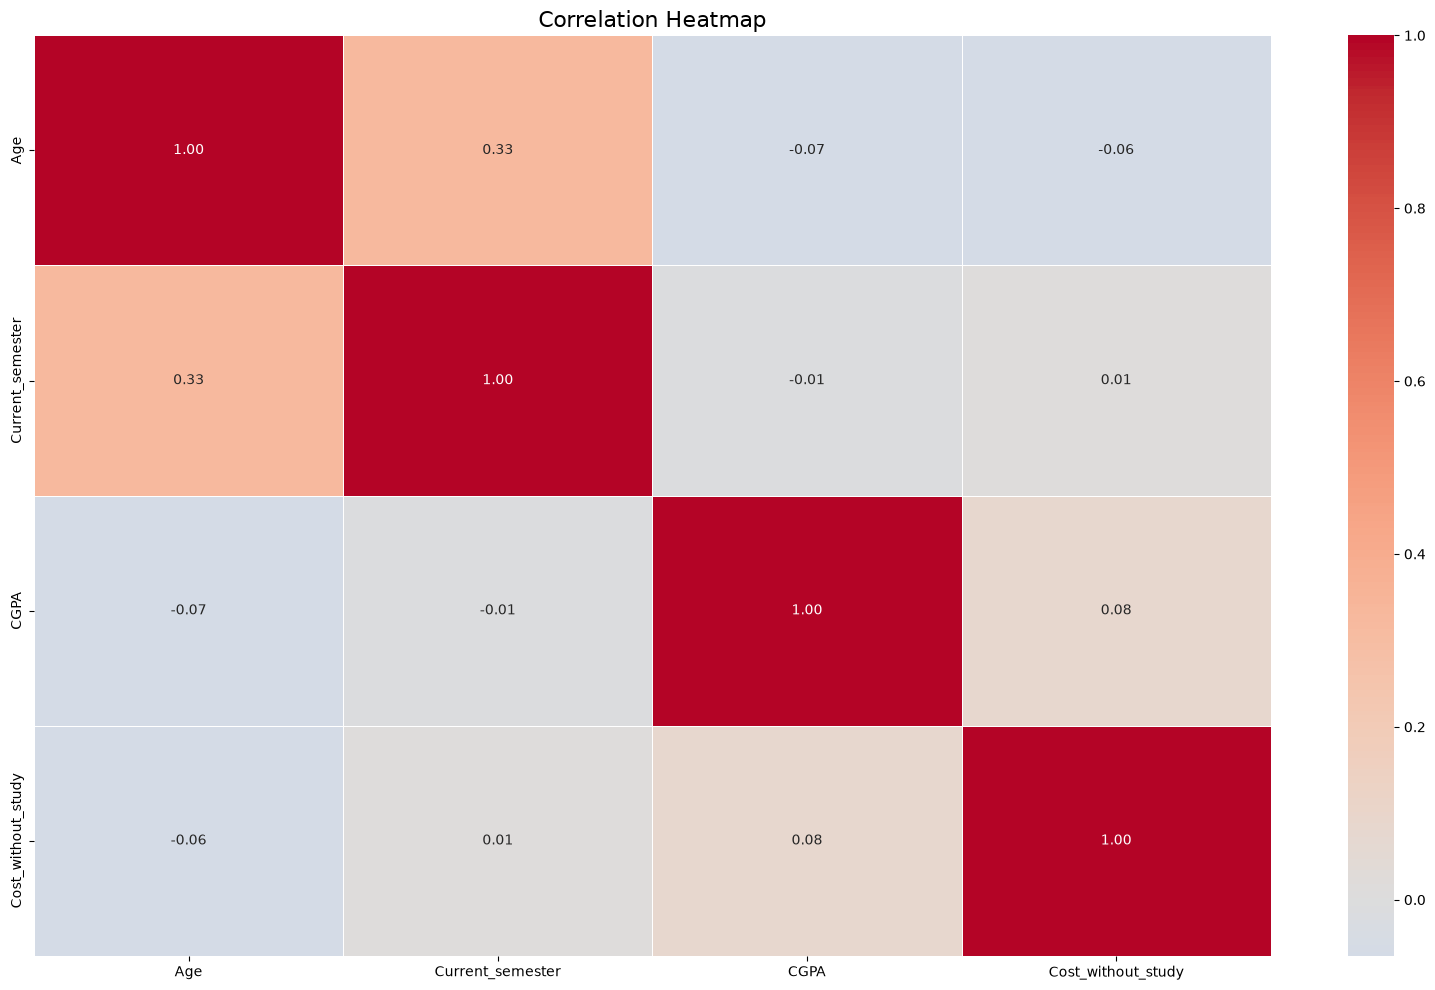

In [3]:
## Outlier
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

print(correlation_matrix)

plt.figure(figsize=(16, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

In [20]:
import pandas as pd
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Depression'])
y = df['Depression']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3571, 12)
X_test: (893, 12)
y_train: (3571,)
y_test: (893,)


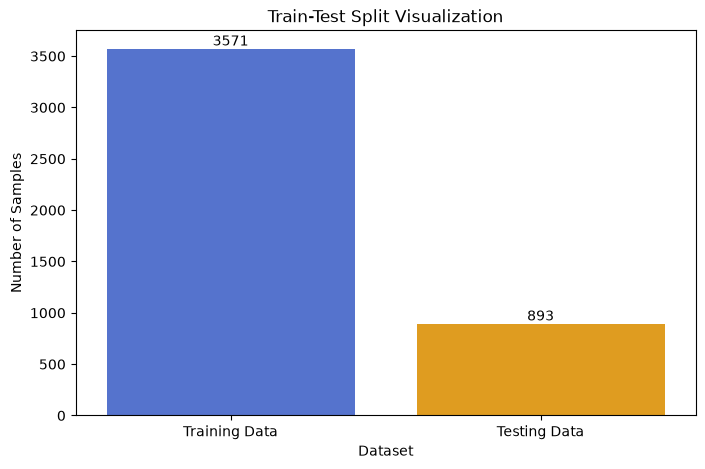

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung jumlah data
train_count = len(X_train)
test_count = len(X_test)

# Membuat visualisasi
plt.figure(figsize=(8, 5))

sns.barplot(
    x=['Training Data', 'Testing Data'],
    y=[train_count, test_count],
    hue=['Training Data', 'Testing Data'],
    palette=['royalblue', 'orange'],
    legend=False
)

plt.title('Train-Test Split Visualization')
plt.xlabel('Dataset')
plt.ylabel('Number of Samples')

# Menampilkan jumlah data
for i, value in enumerate([train_count, test_count]):
    plt.text(i, value, str(value), ha='center', va='bottom')

plt.show()